# Reproducing Figure 3: sampled recurrence counts
Geiping et al. sample the number of times the recurrent block runs during training. Figure 3 shows the distribution of this count. The code below implements equations (1) and (2) in [Section 3.3, page 4](https://arxiv.org/pdf/2502.05171v2#page=4).

### Sample the counts
First draw a normal variable $\tau$ with mean $\log(\bar r)-\sigma^2/2$ and standard deviation $\sigma$. Then draw a Poisson count with rate $e^\tau$ and add one. The shift in the normal mean gives $\mathbb{E}[e^\tau]=\bar r$, so $\mathbb{E}[r]=\bar r+1$.

The paper uses $\bar r=32$ and $\sigma=0.5$. For this reproduction, we use one million independent draws and seed 42. Run all cells in order with NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 1_000_000
r_bar = 32
sigma = 0.5

mu = np.log(r_bar) - sigma**2 / 2
tau = rng.normal(loc=mu, scale=sigma, size=n)
rate = np.exp(tau)
r = rng.poisson(lam=rate) + 1

### Compare with the paper
Count the draws at each integer depth. The depth with the largest count is the sample mode.

In [2]:
counts = np.bincount(r)
mean = r.mean()
median = np.median(r)
mode = counts.argmax()

print("Statistic   Figure 3    Reproduction")
print(f"Mean            33.0    {mean:.3f}")
print(f"Median          29.0    {median:.1f}")
print(f"Mode            24.0    {mode:d}")

Statistic   Figure 3    Reproduction
Mean            33.0    33.002
Median          29.0    29.0
Mode            24.0    24


### Plot the sampled distribution
Each unit-width bar shows the fraction of all draws at that depth. The horizontal axis shows depths up to 150, as in the paper. All draws contribute to the summary statistics and the denominator.

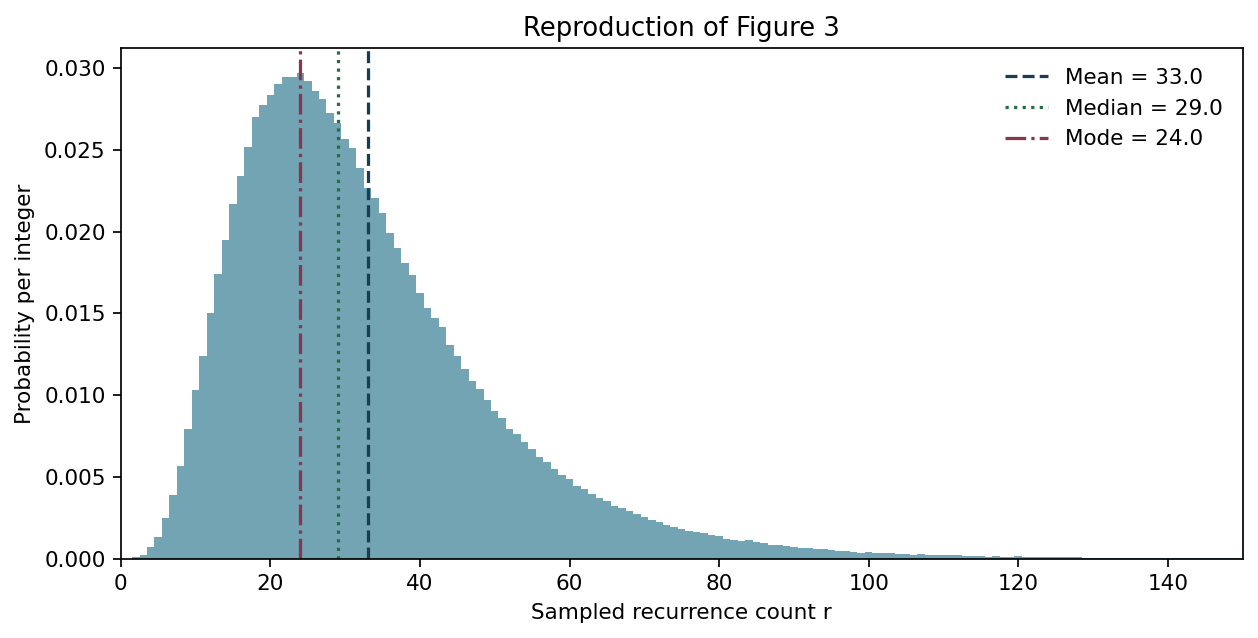

In [3]:
depths = np.arange(len(counts))
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(depths, counts / n, width=1, color="#72a4b3")
for value, label, style, color in [
    (mean, "Mean", "--", "#193e54"),
    (median, "Median", ":", "#286b45"),
    (mode, "Mode", "-.", "#87374d"),
]:
    ax.axvline(value, label=f"{label} = {value:.1f}", ls=style, color=color)
ax.set(xlim=(0, 150), xlabel="Sampled recurrence count r",
       ylabel="Probability per integer", title="Reproduction of Figure 3")
ax.legend(frameon=False)
plt.show()

The simulated mean rounds to 33.0, the median is 29, and the mode is 24, matching the values labeled in Figure 3. The right tail contains occasional large recurrence counts that pull the mean above the median.